# Recipe: Polarimetric imaging with a PSF and a coronagraph

Near-infrared polarised light of an inclined disk with a two-component Henyey-Greenstein phase function: diffraction-limited PSF of an 8-m telescope, a 0.1" coronagraph mask and Q_phi in mJy/arcsec^2.

**Files:** `examples/polarisation_hg.nml`  
**Run time:** about 30 s  
**Manual:** Sect. 16.5 of `docs/manual/dms_manual.pdf`. The same code as a script: `python3 examples/recipes/observed_polarisation.py`.

In [1]:
# Setup: this notebook lives in examples/recipes/ of the repository
import os, sys
if "REPO" not in globals():
    REPO = os.environ.get("DMS_REPO") or os.path.abspath(os.path.join("..", ".."))
sys.path.insert(0, os.path.join(REPO, "python"))      # use the DMS of this repository
os.chdir(REPO)                                        # input files and cache/ are relative to the root
import dms
import numpy as np
import matplotlib.pyplot as plt
print("DMS", dms.__version__)

DMS 2.2.1


peak Q_phi at 1.65 micron: 0.0401 mJy/arcsec^2


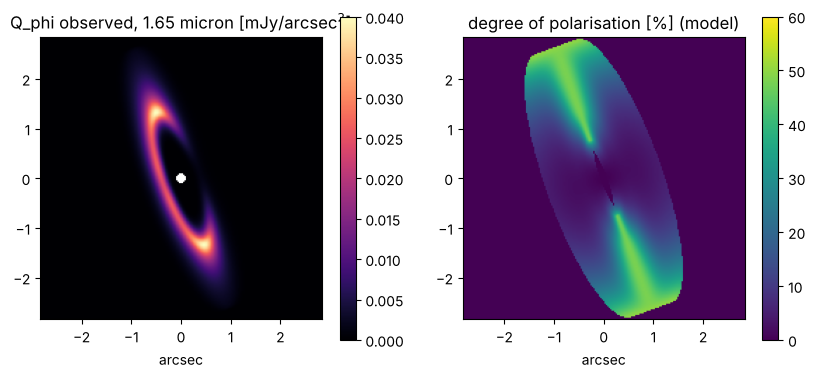

In [2]:
res = dms.Model.from_file("examples/polarisation_hg.nml").run()
qphi = res.image("Qphi", observed=True, unit="mJy/arcsec2")
pol = res.image("poldeg")
half = res.pixel_arcsec * qphi.shape[-1] / 2
print(f"peak Q_phi at {res.wavelength[1]:g} micron: {np.nanmax(qphi[1]):.3g} mJy/arcsec^2")
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
p = ax[0].imshow(qphi[1], origin="lower", cmap="magma", extent=[-half, half, -half, half])
ax[0].set_title(f"Q_phi observed, {res.wavelength[1]:g} micron [mJy/arcsec$^2$]"); plt.colorbar(p, ax=ax[0])
p = ax[1].imshow(100 * pol[1], origin="lower", cmap="viridis", vmin=0, vmax=60, extent=[-half, half, -half, half])
ax[1].set_title("degree of polarisation [%] (model)"); plt.colorbar(p, ax=ax[1])
for a in ax:
    a.set_xlabel("arcsec")
plt.show()

**Result.** The peak of the observed Q_φ at 1.65 µm is 0.04 mJy/arcsec². For Mie polarisation instead of the Henyey–Greenstein law, remove the `&scattering` group of the input file (`phase_function = 'mie'` is the default). `examples/edge_on_disk.nml` is the same kind of observation for a disk seen at i = 88°.